# Peldaño 4: pozos con tasas de extracción $u_i(t)$ en el canal de Graetz (transitorio)

**Objetivo.** Extender la Parte B de `2a_graetz_manzoni_6_5_1` (4 pozos, control bilineal con cotas,
estacionario) al caso **transitorio con tasas que dependen del tiempo**, que es la forma del problema de la
tesis ($Q_{out}(t)$ constante a trozos, sumidero $Q\,\delta_p\,C$ en `step_time`). Lo nuevo respecto a los
peldaños 2 y 3 es la combinación: control **bilineal** + **tiempo** + **cotas**, con un control finito-dimensional
por intervalo. No hay resultado publicado: la referencia es nuestro FEM refinado (receta de §9 de Graetz).

El código está en `pozos_nucleo.py` (problema transitorio sobre las discretizaciones de `graetz_nucleo`) y
`pozos_benchmark.py` (referencia y benchmark).

## Ficha de lectura

**El problema, en palabras.** No está resuelto en el libro: es la **extensión** de la Parte B de Graetz (§7 de
`2a`) hacia la forma del problema de la tesis. Por el canal de Graetz entra un **pulso** de contaminante. Cuatro pozos
pueden extraer con tasas $u_i(t)$ constantes a trozos (20 intervalos) y se quiere proteger la zona final del canal
durante todo el horizonte, con tasas acotadas o sin cotas. Es un control bilineal transitorio con cotas, como
$Q_{out}(t)$ en la tesis.

**Cómo lo implementamos (§2).** Las mismas discretizaciones de `graetz_nucleo` (RBF-FD con fantasmas y FEM), esquema
$\theta$ escrito por filas (las condiciones de frontera, implícitas), una LU por intervalo de control reutilizada en el
estado y en el adjunto, gradiente exacto (Taylor de orden 2), y CG-PR+ proyectado frente a L-BFGS-B.

**Cómo comparamos (§4–6).** Como no hay libro, la referencia es nuestro FEM con $n=20/40/80$ y Richardson (orden
observado 2.05). Se valida el óptimo de RBF-FD con la evaluación cruzada $J_{FEM}(\hat u_{RBF})$.

| resultado | valor |
|---|---|
| $J^*$ referencia, libre / con cotas | 2.82523e-4 / 3.10337e-4 (±1e-7) |
| RBF-FD $n=20$ | +1.06 % / +1.32 %; evaluación cruzada +0.002 % (sin óptimo espurio) |
| tasas $u(t)$ frente al mejor caudal constante | −42 % / −36 % de $J^*$; el control se apaga al final (efecto de horizonte) |
| optimizador | L-BFGS-B 42/38 evaluaciones; CG-PR+ 74/276 |

**Mapa:** §1 problema · §2 discretización y Taylor · §3 dinámica sin control · §4 óptimo (CG vs L-BFGS-B, FEM vs
RBF-FD, variable vs constante) · §5 número de intervalos y $\theta$ · §6 referencia y benchmark
(`pozos_benchmark.py`) · §7 conclusiones.

## 1. El problema

Canal $\Omega=(0,4)\times(0,1)$, campo de Graetz $\mathbf b=(1.5\,x_2(1-x_2),0)$, $\mu=0.1$, $T=20$. Un **pulso**
de contaminante entra por $x_1=0$ y se quiere proteger $\Omega_{obs}=\{x_1>3.4\}$ durante todo $[0,T]$:
$$
\partial_t y-\mu\Delta y+\mathbf b\cdot\nabla y+\sum_{i=1}^{4}u_i(t)\,\psi_i(x)\,y=0,\qquad
y=g(t)\ \text{en } x_1=0,\quad \mu\partial_n y=0\ \text{en el resto},\quad y(\cdot,0)=0,
$$
$$
\min_{0\le u_i(t)\le u_{\max}}\ J(u)=\frac12\int_0^T\!\!\int_{\Omega_{obs}}y^2\,dx\,dt+\frac\beta2\sum_i\int_0^T u_i(t)^2\,dt,
$$
con $g(t)=\sin^2(\pi t/2)$ en $[0,2]$ y $0$ después (suave, compatible con $y(\cdot,0)=0$), los mismos pozos
gaussianos que en el peldaño 2 ($\sigma=0.08$, $x_i\in\{(1.5,0.5),(2,0.3),(2,0.7),(2.6,0.5)\}$) y $\beta=10^{-4}$.
Las tasas son **constantes a trozos** en $M=20$ intervalos de longitud $\tau=1$: $u\in\mathbb R^{M\times 4}$.

Dos escenarios: **libre** ($u_{\max}=5$, no se activa) y **con cotas** ($u_{\max}=0.3$, por debajo del pico del
óptimo libre ⇒ conjunto activo que cambia en el tiempo).

> **Nota (revisión del 28-oct-2026, ver `../notebooks/3_cuadrado_pozo`).** Aquí el pozo es un sumidero $u_i\psi_i\,y$ en el
> transporte, y eso es correcto **porque la velocidad de Graetz no siente el pozo** ($\nabla\cdot\mathbf b=0$). En el
> acuífero de la tesis el pozo sí cambia el flujo ($\nabla\cdot\mathbf q=-Q\delta_p$), y entonces la extracción ya
> está dentro de $\mathbf q\cdot\nabla C$ en la forma no conservativa. Añadir además el sumidero ($W_-$ del
> simulador) cuenta la extracción dos veces. Este modelo de pozo como reacción **no** se traslada tal cual al
> simulador.

In [1]:
import time
import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from scipy.optimize import minimize
import pozos_nucleo as PN
import pozos_benchmark as PB

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
n = 20
f, g = PB.fem(n), PB.rbf(n)

## 2. Discretización (discretizar y luego optimizar)

* **Espacio:** RBF-FD con nodos fantasma y FEM $\mathbb P_1$ de `graetz_nucleo` (kind='canal'), retícula
  $h=1/20$ (los mismos nodos para los dos métodos). Sumidero con masa concentrada en el FEM; en colocación, sólo
  en las filas de EDP.
* **Tiempo:** esquema $\theta$ ($\theta=\tfrac12$), $\Delta t=1/n$, escrito por filas:
  $L_m y^{n+1}=R_m y^n+g(t_{n+1})\,f$, con $L_m=D/\Delta t+\Theta K(u^m)$, $R_m=D/\Delta t-(I-\Theta)K(u^m)$ y
  $K(u)=A+\sum_i u_iS_i$. $D$ es la masa de las filas diferenciales (colocación: indicador de las filas de EDP;
  FEM: masa consistente) y $\Theta=\theta$ en ellas y $1$ en las algebraicas (Dirichlet y condición de Neumann
  sobre el fantasma), de modo que las condiciones de frontera se imponen en $t_{n+1}$.
* **Funcional:** trapecio en el tiempo, $J_h=\tfrac12\sum_n w_n\,y^{n\top}M_{obs}y^n+\tfrac\beta2\tau\sum_{m,i}(u_i^m)^2$.
* **Adjunto discreto:** $L_{N_t-1}^\top\lambda^{N_t}=w_{N_t}M_{obs}y^{N_t}$,
  $L_{n-1}^\top\lambda^n=w_nM_{obs}y^n+R_n^\top\lambda^{n+1}$, y
  $$\frac{\partial J_h}{\partial u_i^m}=\beta\tau u_i^m-\sum_{n\in m}(\lambda^{n+1})^\top S_i\big(\theta y^{n+1}+(1-\theta)y^n\big).$$
  Es la fórmula de la escalera ($-\Delta t\,p^\top S_iy$) con la cuadratura del esquema $\theta$; $\lambda$ ya
  lleva el factor $\Delta t$.
* **Coste:** una LU por intervalo de control (20 por evaluación), compartida por el estado y el adjunto
  (`trans='T'`). Cada evaluación de $(J,\nabla J)$ = 1 barrido hacia adelante + 1 hacia atrás.
* **Optimizador:** el CG-PR+ proyectado con Wolfe del peldaño 2 (`ncg_proj`), sin cambios; L-BFGS-B como control.

### 2.1 Test de Taylor (orden 2 ⇒ gradiente exacto)

In [2]:
rng = np.random.default_rng(0)
for name, d in (("FEM", f), ("RBF-FD", g)):
    for theta in (0.5, 1.0):
        tw = PB.problema(d, n, 5.0, theta=theta)
        u = rng.uniform(0.1, 0.6, tw.M * tw.K); du = rng.standard_normal(u.size)
        J0, g0, _ = tw.Jg(u)
        r = np.array([abs(tw.J(u + e * du) - J0 - e * g0 @ du) for e in 10.0 ** -np.arange(1, 6)])
        print(f"{name:6s} θ={theta}: tasas {np.round(np.log10(r[:-1] / r[1:]), 2)}")

FEM    θ=0.5: tasas [2.01 2.   2.   2.  ]


FEM    θ=1.0: tasas [2. 2. 2. 2.]


RBF-FD θ=0.5: tasas [1.99 2.   2.   2.  ]


RBF-FD θ=1.0: tasas [2. 2. 2. 2.]


## 3. Dinámica sin control

El pulso tarda ≈3 unidades en llegar al primer pozo y ≈6 en llegar a $\Omega_{obs}$; con $\mu=0.1$ se ensancha
mucho, así que $\Omega_{obs}$ ve contaminante hasta $t\approx20$ ($T=20$ recoge el 95 % de la exposición que se
acumularía con $T=30$).

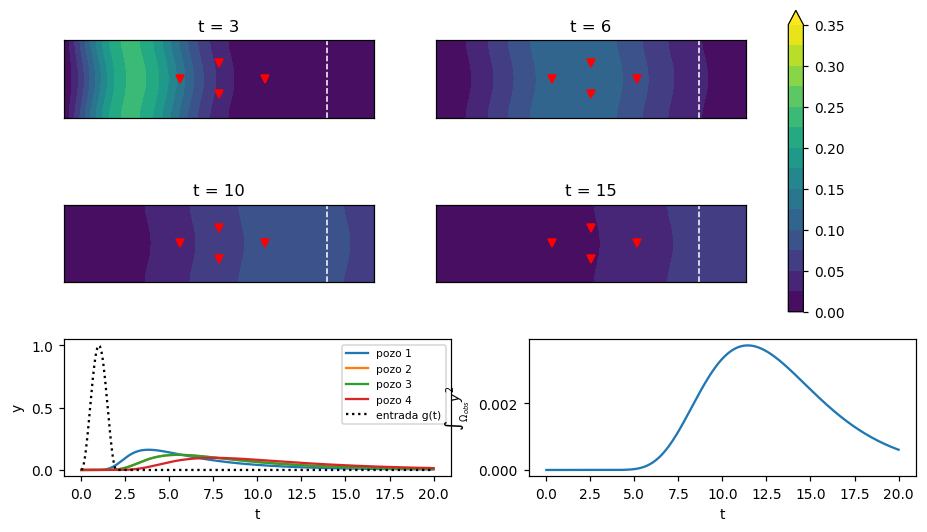

J(0) = 1.52046e-02


In [3]:
tw0 = PB.problema(f, n, 5.0)
Y0 = tw0.forward(tw0.zeros().reshape(tw0.M, tw0.K))
obs0 = np.einsum("ni,ni->n", Y0, (tw0.Mobs @ Y0.T).T)
iw = [np.argmin(((f.P - c) ** 2).sum(1)) for c in PN.XW]
tri = mtri.Triangulation(f.P[:, 0], f.P[:, 1], f.T)
fig = plt.figure(figsize=(10, 5.5))
for k, tk in enumerate((3, 6, 10, 15)):
    a = fig.add_subplot(3, 2, k + 1)
    tc = a.tricontourf(tri, Y0[int(tk * n)], np.linspace(0, 0.35, 15), cmap="viridis", extend="max")
    a.plot(*np.array(PN.XW).T, "rv", ms=5); a.axvline(3.4, color="w", ls="--", lw=1)
    a.set_title(f"t = {tk}"); a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([])
plt.colorbar(tc, ax=fig.axes[:4])
a = fig.add_subplot(3, 2, 5)
for i in range(4):
    a.plot(tw0.t, Y0[:, iw[i]], label=f"pozo {i + 1}")
a.plot(tw0.t, PN.pulso(tw0.t), "k:", label="entrada g(t)"); a.set(xlabel="t", ylabel="y"); a.legend(fontsize=7)
a = fig.add_subplot(3, 2, 6)
a.plot(tw0.t, obs0); a.set(xlabel="t", ylabel=r"$\int_{\Omega_{obs}} y^2$")
plt.show()
print(f"J(0) = {tw0.J(tw0.zeros()):.5e}")

## 4. Óptimo sin cotas: CG-PR+ proyectado vs L-BFGS-B, FEM vs RBF-FD, tasas variables vs constantes

Se resuelve con el FEM desde $u=0$ con los dos optimizadores, y con RBF-FD arrancando del óptimo FEM (el control
vive en $\mathbb R^{M\times4}$ y no depende de la malla). Como contraste, el mejor control **constante en el
tiempo** ($u_i(t)\equiv c_i$, el análogo del peldaño 2).

In [4]:
def lbfgsb_hist(tw, u0=None):
    hist = []
    def fg(v):
        J, G, _ = tw.Jg(v); hist.append(J); return J, G
    r = minimize(fg, tw.zeros() if u0 is None else u0, jac=True, method="L-BFGS-B",
                 bounds=[(0, tw.umax)] * (tw.M * tw.K), options={"gtol": 1e-8 * tw._g0, "ftol": 1e-15})
    return r.x, np.array(hist)


res = {}
for esc, umax in PB.ESCENARIOS.items():
    tf, tg = PB.problema(f, n, umax), PB.problema(g, n, umax)
    tf._g0 = np.abs(tf.Jg(tf.zeros())[1]).max()
    t0 = time.time(); tf.nsolves = 0
    u_cg, h_cg = PN.ncg_proj(tf, tf.zeros(), tol=1e-7, maxit=300); ev_cg, s_cg = tf.nsolves, time.time() - t0
    t0 = time.time(); tf.nsolves = 0
    u_lb, h_lb = lbfgsb_hist(tf); ev_lb, s_lb = tf.nsolves, time.time() - t0
    t0 = time.time()
    u_rb, h_rb, ev_rb = PB.optimo(tg, u_lb); s_rb = time.time() - t0
    c_f, h_c, _ = PB.optimo(PN.ConstantWells(tf))
    J0 = tf.J(tf.zeros())
    res[esc] = dict(tf=tf, u=u_lb, u_rb=u_rb, c=c_f, h_cg=h_cg, h_lb=h_lb, J0=J0, Jc=h_c[-1])
    print(f"--- {esc} (u_max = {umax}) ---   J(0) = {J0:.5e}")
    print(f"FEM  CG-PR+ proy. : J* = {h_cg[-1]:.6e}  {len(h_cg) - 1:3d} it  {ev_cg:3d} evaluaciones  {s_cg:4.0f}s")
    print(f"FEM  L-BFGS-B     : J* = {h_lb[-1]:.6e}  {ev_lb:3d} evaluaciones  {s_lb:4.0f}s   "
          f"max|Δu| vs CG = {np.abs(u_lb - u_cg).max():.1e}")
    print(f"RBF  L-BFGS-B     : J* = {h_rb[-1]:.6e}  {ev_rb:3d} evaluaciones  {s_rb:4.0f}s (arranque: óptimo FEM)  "
          f"J_FEM(û_RBF) = {tf.J(u_rb):.6e}  ‖û_RBF−û_FEM‖/‖û_FEM‖ = {np.linalg.norm(u_rb - u_lb) / np.linalg.norm(u_lb):.1e}")
    print(f"constante en t    : J* = {h_c[-1]:.6e}  c = {np.round(c_f, 4)}")
    print(f"reducción: u(t) {100 * (1 - h_lb[-1] / J0):.2f} %, constante {100 * (1 - h_c[-1] / J0):.2f} %;  "
          f"u(t) baja J* un {100 * (1 - h_lb[-1] / h_c[-1]):.0f} % respecto al mejor control constante")

--- libre (u_max = 5.0) ---   J(0) = 1.52046e-02
FEM  CG-PR+ proy. : J* = 2.847632e-04   12 it   74 evaluaciones    10s
FEM  L-BFGS-B     : J* = 2.847632e-04   42 evaluaciones     5s   max|Δu| vs CG = 6.2e-06
RBF  L-BFGS-B     : J* = 2.855198e-04   20 evaluaciones    12s (arranque: óptimo FEM)  J_FEM(û_RBF) = 2.847693e-04  ‖û_RBF−û_FEM‖/‖û_FEM‖ = 4.1e-03
constante en t    : J* = 4.874653e-04  c = [0.2727 0.2607 0.2607 0.2787]
reducción: u(t) 98.13 %, constante 96.79 %;  u(t) baja J* un 42 % respecto al mejor control constante


--- cotas (u_max = 0.3) ---   J(0) = 1.52046e-02
FEM  CG-PR+ proy. : J* = 3.132687e-04   32 it  276 evaluaciones    45s
FEM  L-BFGS-B     : J* = 3.132687e-04   38 evaluaciones     7s   max|Δu| vs CG = 1.0e-05
RBF  L-BFGS-B     : J* = 3.144340e-04   18 evaluaciones    18s (arranque: óptimo FEM)  J_FEM(û_RBF) = 3.132745e-04  ‖û_RBF−û_FEM‖/‖û_FEM‖ = 4.9e-03
constante en t    : J* = 4.874653e-04  c = [0.2727 0.2607 0.2607 0.2787]
reducción: u(t) 97.94 %, constante 96.79 %;  u(t) baja J* un 36 % respecto al mejor control constante


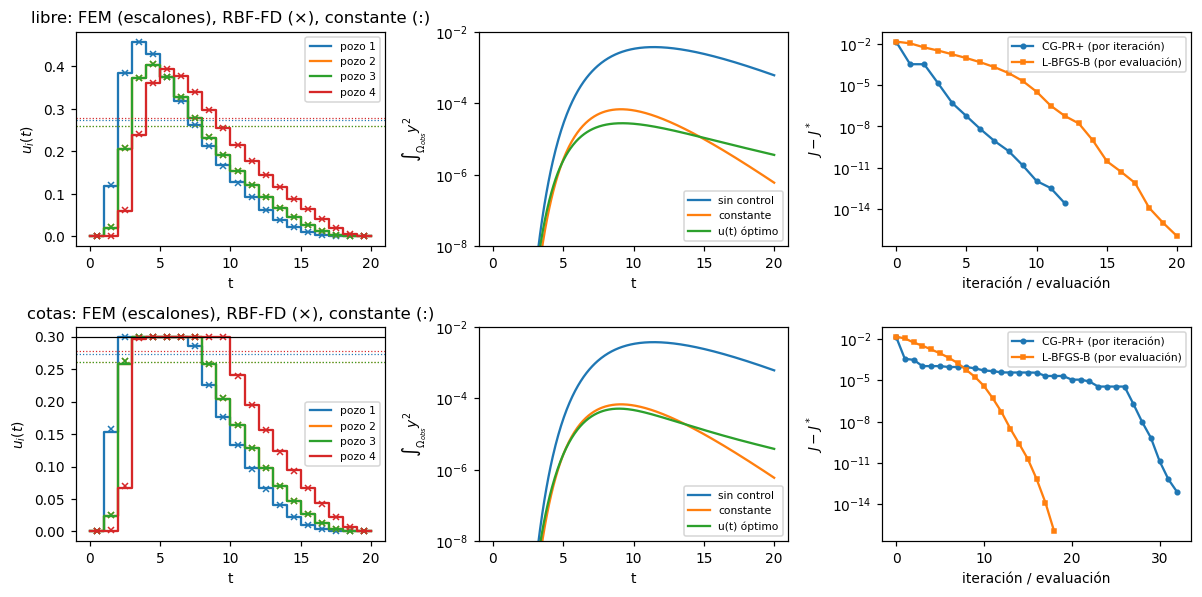

In [5]:
tm = np.arange(tw0.M) + 0.5
fig, ax = plt.subplots(2, 3, figsize=(11, 5.5))
for k, esc in enumerate(PB.ESCENARIOS):
    r_ = res[esc]; tf = r_["tf"]
    U, Ur = r_["u"].reshape(tf.M, tf.K), r_["u_rb"].reshape(tf.M, tf.K)
    a = ax[k, 0]
    for i in range(4):
        a.step(np.r_[0, tm + 0.5], np.r_[U[0, i], U[:, i]], where="pre", color=f"C{i}", label=f"pozo {i + 1}")
        a.plot(tm, Ur[:, i], "x", color=f"C{i}", ms=4)
        a.axhline(r_["c"][i], color=f"C{i}", ls=":", lw=0.8)
    if esc == "cotas":
        a.axhline(tf.umax, color="k", lw=0.8)
    a.set(xlabel="t", ylabel="$u_i(t)$", title=f"{esc}: FEM (escalones), RBF-FD (×), constante (:)"); a.legend(fontsize=7)
    Yo = tf.forward(U); Yc = tf.forward(np.tile(r_["c"], (tf.M, 1)))
    a = ax[k, 1]
    for Y, lab in ((Y0, "sin control"), (Yc, "constante"), (Yo, "u(t) óptimo")):
        a.semilogy(tf.t, np.einsum("ni,ni->n", Y, (tf.Mobs @ Y.T).T) + 1e-12, label=lab)
    a.set(xlabel="t", ylabel=r"$\int_{\Omega_{obs}}y^2$", ylim=(1e-8, 1e-2)); a.legend(fontsize=7)
    a = ax[k, 2]
    Jst = min(r_["h_cg"][-1], r_["h_lb"][-1])
    a.semilogy(r_["h_cg"] - Jst + 1e-16, "o-", ms=3, label="CG-PR+ (por iteración)")
    a.semilogy(r_["h_lb"] - Jst + 1e-16, "s-", ms=3, label="L-BFGS-B (por evaluación)")
    a.set(xlabel="iteración / evaluación", ylabel="$J-J^*$"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

**Lectura.**
* El óptimo tiene la forma esperada: cada pozo bombea **mientras le pasa el penacho** (primero el pozo 1, después los
  pozos 2–3, que son simétricos y dan el mismo control, y por último el 4) y **apaga al final**. El apagado final
  es un efecto de horizonte: lo que pasa por los pozos después de $t\approx17$ ya no llega a $\Omega_{obs}$ antes de
  $T$, así que extraer ahí sólo cuesta $\beta$. En la tesis pasará lo mismo con cualquier $J$ integrado en $[0,T]$:
  el óptimo «sabe» que el mundo acaba en $T$.
* Con cotas, el conjunto activo $u=u_{\max}$ cubre el paso del frente (5 intervalos por pozo) y el control se
  **desplaza** (el pozo 4 alarga su bombeo): la proyección del optimizador lo identifica sin ayuda.
* Dejar que las tasas varíen en el tiempo vale la pena: $J^*$ baja 42 % (libre) y 36 % (con cotas) respecto al
  mejor control constante.
* **Optimizador.** CG-PR+ proyectado y L-BFGS-B llegan al mismo óptimo ($|\Delta u|\sim10^{-5}$), pero el CG gasta
  ≈6 evaluaciones por iteración en la búsqueda de Wolfe ($c_2=0.1$) y, con cotas, se reinicia cada vez que cambia
  el conjunto activo. **Esto corrige la conclusión del peldaño 2** («CG ≈ L-BFGS»): allí había 4 variables; con
  80 variables, con la misma tolerancia, L-BFGS-B es 1.8× más barato sin cotas y 7× con cotas. El benchmark usa
  L-BFGS-B.
* **Un defecto de `ncg_proj` que conviene no portar:** su tolerancia es relativa al gradiente proyectado *del
  punto inicial*. Arrancando cerca del óptimo exige un gradiente diminuto y gasta más que arrancando de cero (lo
  vimos al arrancar el RBF-FD desde el óptimo FEM: 120 evaluaciones, frente a 20 de L-BFGS-B). El criterio debe ser absoluto o relativo a
  $\nabla J(0)$.

## 5. ¿Cuántos intervalos de control hacen falta? y $\theta=1$ frente a Crank–Nicolson

In [6]:
JM = {}
for esc, umax in PB.ESCENARIOS.items():
    u20 = res[esc]["u"].reshape(20, 4)
    JM[esc] = {}
    for M in (1, 5, 10, 20, 40):
        tm_ = PB.problema(f, n, umax, M=M)
        u0 = np.repeat(u20, M // 20, 0).ravel() if M >= 20 else u20.reshape(M, 20 // M, 4).mean(1).ravel()
        JM[esc][M] = PB.optimo(tm_, u0)[1][-1]
    tt = PB.problema(f, n, umax, theta=1.0)
    J1 = PB.optimo(tt, res[esc]["u"])[1][-1]
    d = np.diff([JM[esc][M] for M in (5, 10, 20, 40)])
    print(f"{esc}: J*(M) = " + "  ".join(f"M={M}: {v:.5e}" for M, v in JM[esc].items())
          + f"   cocientes de diferencias {np.round(d[:-1] / d[1:], 2)}")
    print(f"       θ = 1 (Euler implícito): J* = {J1:.5e}  ({100 * (J1 / res[esc]['h_lb'][-1] - 1):+.2f} % vs CN)")

libre: J*(M) = M=1: 4.87465e-04  M=5: 3.19408e-04  M=10: 2.89462e-04  M=20: 2.84763e-04  M=40: 2.83406e-04   cocientes de diferencias [6.37 3.46]
       θ = 1 (Euler implícito): J* = 2.86623e-04  (+0.65 % vs CN)


cotas: J*(M) = M=1: 4.87465e-04  M=5: 3.43362e-04  M=10: 3.16425e-04  M=20: 3.13269e-04  M=40: 3.11526e-04   cocientes de diferencias [8.53 1.81]
       θ = 1 (Euler implícito): J* = 3.12881e-04  (-0.12 % vs CN)


$J^*(M)$ decrece con $M$ (espacios de control anidados). Sin cotas los cocientes de diferencias (6.4, 3.5) indican
orden ≈2 en $\tau$; con cotas son irregulares (8.5, 1.8) porque el conjunto activo cambia con $M$. En ambos casos
pasar de $M=20$ a $M=40$ sólo baja $J^*$ un 0.5 %: $M=20$ está a ≈1 % del control continuo en el tiempo.
Euler implícito cambia $J^*$ menos de 1 % (+0.65 % y −0.12 %) con $\Delta t=0.05$: el problema es
suave en el tiempo (pulso $\sin^2$ y observación integrada, sin capa límite como la del peldaño 3).

## 6. Referencia y benchmark

Referencia: FEM, CN, $\Delta t=1/n$, $n=20,40,80$, $M=20$, cada malla arrancando del óptimo de la anterior, y
Richardson con el orden observado. Nivel rápido: FEM desde cero y RBF-FD desde el óptimo FEM en $n=20$, con
evaluación cruzada $J_{FEM}(\hat u_{RBF})$, error del control contra el de $n=80$ y optimalidad (gradiente
proyectado) del óptimo RBF-FD.

In [7]:
ref = json.loads(PB.REF.read_text())
for esc, e in ref["escenarios"].items():
    for k in ("J0", "J", "Jc"):
        v = e[k]
        print(f"{esc} {k:2s}: {v['valor']:.7e} ± {v['error_estimado_n80']:.0e}  (orden {v['orden']:.2f}, niveles "
              f"{np.array(v['niveles'])})")
    print(f"      ‖u_40 − u_80‖/‖u_80‖ = {e['dif_u_n40_n80']:.1e}")
t0 = time.time()
r = PB.nivel(20, ref)
fl = PB.verificar(r, ref)
print("\nRESULTADO:", "OK" if not fl else fl, f"({time.time() - t0:.0f}s)")

libre J0: 1.5204682e-02 ± 2e-09  (orden 2.58, niveles [0.01520461 0.01520467 0.01520468])
libre J : 2.8252299e-04 ± 1e-07  (orden 2.05, niveles [0.00028476 0.00028306 0.00028265])
libre Jc: 4.8431778e-04 ± 2e-07  (orden 2.05, niveles [0.00048747 0.00048508 0.0004845 ])
      ‖u_40 − u_80‖/‖u_80‖ = 4.8e-04
cotas J0: 1.5204682e-02 ± 2e-09  (orden 2.58, niveles [0.01520461 0.01520467 0.01520468])
cotas J : 3.1033687e-04 ± 2e-07  (orden 2.05, niveles [0.00031327 0.00031105 0.00031051])
cotas Jc: 4.8431778e-04 ± 2e-07  (orden 2.05, niveles [0.00048747 0.00048508 0.0004845 ])
      ‖u_40 − u_80‖/‖u_80‖ = 3.6e-04

n = 20: RBF-FD 1880 incógnitas, FEM 1701; 400 pasos, M = 20
  esc |     J*_ref |     J*_FEM  err%  ev |     J*_RBF  err%  ev   gproj | J_FEM(û_RBF)    Δ% |  ‖Δu‖% |    s


libre | 2.82523e-04 | 2.84763e-04  0.79  42 | 2.85520e-04  1.06  20 2.1e-09 |  2.84769e-04  0.00 |   0.56 |   25


cotas | 3.10337e-04 | 3.13269e-04  0.94  38 | 3.14434e-04  1.32  18 3.1e-09 |  3.13274e-04  0.00 |   0.59 |   25

RESULTADO: OK (50s)


## 7. Conclusiones

| | libre ($u_{\max}=5$) | con cotas ($u_{\max}=0.3$) |
|---|---|---|
| $J(0)$ (sin bombeo) | 1.52047e-2 | 1.52047e-2 |
| $J^*$ mejor control constante | 4.8432e-4 | 4.8432e-4 (cotas inactivas) |
| $J^*$ referencia, $u(t)$ con $M=20$ | **2.82523e-4 ± 1e-7** (orden 2.05) | **3.10337e-4 ± 2e-7** (orden 2.05) |
| FEM $n=20$ / RBF-FD $n=20$ | +0.79 % / +1.06 % | +0.94 % / +1.32 % |
| $J_{FEM}(\hat u_{RBF})$ vs óptimo FEM | +0.002 % | +0.002 % |
| $\lVert\hat u_{RBF}-u_{ref}\rVert/\lVert u_{ref}\rVert$ | 0.56 % | 0.59 % |
| evaluaciones: CG-PR+ / L-BFGS-B (FEM, desde 0) | 74 / 42 | 276 / 38 |
| $J^*$ con $u(t)$ frente al mejor constante | −42 % | −36 % |

1. **La extensión al tiempo funciona sin trucos nuevos.** El adjunto discreto del esquema $\theta$ escrito por filas
   (filas algebraicas implícitas) da orden 2 en el test de Taylor para FEM y RBF-FD, con $\theta=\tfrac12$ y $1$.
2. **RBF-FD es fiable con control interior también en transitorio**: ≈1 % de $J^*$ en $n=20$ (el FEM, 0.8–0.9 %),
   control a 0.6 % del de referencia y evaluación cruzada a 0.002 %: sin óptimo espurio.
3. **La referencia es sólida**: el orden observado es 2.05 en los dos escenarios (CN + $\mathbb P_1$, datos
   suaves), y $J^*$ queda a $\pm10^{-7}$ relativo.
4. **Las tasas variables en el tiempo valen la pena** (−42 % / −36 % de $J^*$ frente al mejor constante) y el
   óptimo tiene un **efecto de horizonte** (apaga al final) que cualquier $J$ integrado en $[0,T]$ tendrá.
5. **$M=20$ intervalos bastan** (≈1 % del control continuo; doblar $M$ baja $J^*$ 0.5 %).
6. **Optimizador — corrección del peldaño 2:** con 80 variables y cotas activas, L-BFGS-B es más barato
   que el CG-PR+ proyectado con Wolfe (1.8× sin cotas, 7× con cotas). Para la tesis: usar L-BFGS-B (o el `trust-constr` actual) antes que portar
   `ncg_proj`; si se porta, con criterio de parada absoluto y búsqueda lineal más barata.
7. **Coste:** RBF-FD rellena mucho más que FEM en la LU (30 vecinos por fila: 1.8M frente a 0.4M no nulos en
   $h=1/40$), y una evaluación transitoria cuesta $M$ factorizaciones. El nivel rápido tarda ≈40 s (frente a ≈8 s de
   los peldaños 1 y 3). En el simulador, con $Q$ constante a trozos, vale lo mismo: una factorización por intervalo
   de control, reutilizada por estado y adjunto.